# ChickenStress — 03. Evaluasi & Prediksi Tiap Eksperimen
### Bagian 3 dari 3 (`01_image_processing.ipynb` → `02_models.ipynb` → `03_evaluate.ipynb`)

Melanjutkan dari `02_models.ipynb`. Alur evaluasi **tetap sama seperti notebook awal** (IoU ≥ 0.5 lalu bandingkan akurasi klasifikasi pada `yolo_detect_dataset/images/test`) — perubahan: evaluasi test sekarang dijalankan dan **disimpan untuk setiap dari 6 eksperimen**, bukan cuma konfigurasi terbaik. Untuk tiap eksperimen disimpan:
- `classification_report.txt` (precision/recall/F1 per kelas)
- `confusion_matrix.png`

ke folder baru `WORK_DIR/evaluation_results/<nama_eksperimen>/`.

In [3]:
import os
import json
import random
import shutil
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torchvision.transforms.functional as TF

pd.set_option("display.max_columns", None)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Reproducibility seed set to", SEED)

Reproducibility seed set to 42


## 0. Muat artefak dari `01_image_processing.ipynb` dan checkpoint dari `02_models.ipynb` (PATCH — bridging antar notebook)

In [4]:
# Samakan RAW_DIR dengan notebook 1 hanya untuk menghitung ulang WORK_DIR/lokasi file artefak.
RAW_DIR = r"E:\Magang DSC\Code - Image Classification Workflow\Data"
WORK_DIR = os.path.join(os.path.dirname(RAW_DIR), "Data_working")

ARTIFACT_PATH = os.path.join(WORK_DIR, "pipeline_artifacts.pkl")
with open(ARTIFACT_PATH, "rb") as f:
    artifact_state = pickle.load(f)
globals().update(artifact_state)

EXPERIMENT_REGISTRY_PATH = os.path.join(WORK_DIR, "experiment_checkpoints.pkl")
with open(EXPERIMENT_REGISTRY_PATH, "rb") as f:
    experiment_checkpoints = pickle.load(f)

# PATCH (fix): EXPLORE_EPOCHS tadinya cuma ada di 02_models.ipynb dan bikin NameError
# di cell perbandingan bar chart. Sekarang diambil dari _meta yang sudah disimpan di sana.
_meta = experiment_checkpoints.get("_meta", {})
EXPLORE_EPOCHS = _meta.get("EXPLORE_EPOCHS", "N/A")
EARLY_STOPPING_PATIENCE = _meta.get("EARLY_STOPPING_PATIENCE", "N/A")

print("Artefak dimuat dari:", ARTIFACT_PATH)
print("Checkpoint eksperimen dimuat dari:", EXPERIMENT_REGISTRY_PATH)
for name, info in experiment_checkpoints.items():
    if name == "_meta":
        continue
    print(" -", name, "->", info)

Artefak dimuat dari: E:\Magang DSC\Code - Image Classification Workflow\Data_working\pipeline_artifacts.pkl
Checkpoint eksperimen dimuat dari: E:\Magang DSC\Code - Image Classification Workflow\Data_working\experiment_checkpoints.pkl
 - 1. YOLOv11 (satu tahap) -> {'type': 'yolo', 'checkpoint': 'E:\\Magang DSC\\Code - Image Classification Workflow\\runs\\detect\\ChickenStress\\config1_stage2_finetune\\weights\\best.pt'}
 - 2. DINOv2 (satu tahap) -> {'type': 'torchvision_detector', 'backbone': 'dinov2', 'checkpoint': 'E:\\Magang DSC\\Code - Image Classification Workflow\\Data_working\\checkpoints\\config2_dinov2_detector.pt'}
 - 3. EfficientNetV2 (satu tahap) -> {'type': 'torchvision_detector', 'backbone': 'effnetv2', 'checkpoint': 'E:\\Magang DSC\\Code - Image Classification Workflow\\Data_working\\checkpoints\\config3_effnetv2_detector.pt'}
 - 4. YOLOv11 + DINOv2 -> {'type': 'two_stage', 'classifier': 'dinov2', 'checkpoint': 'E:\\Magang DSC\\Code - Image Classification Workflow\\Data_w

## 1. Bangun ulang arsitektur & muat bobot tiap model (PATCH — bridging antar notebook)

Arsitektur di bawah ini identik dengan yang dipakai untuk training di `02_models.ipynb` — dibutuhkan supaya `load_state_dict` bisa memetakan bobot checkpoint ke model yang tepat.

In [5]:
from ultralytics import YOLO
from transformers import Dinov2Model
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import MultiScaleRoIAlign
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

class Dinov2Backbone(nn.Module):
    def __init__(self, model_name="facebook/dinov2-small", patch_size=14):
        super().__init__()
        self.dinov2 = Dinov2Model.from_pretrained(model_name)
        self.patch_size = patch_size
        self.out_channels = self.dinov2.config.hidden_size

    def forward(self, x):
        h, w = x.shape[-2] // self.patch_size, x.shape[-1] // self.patch_size
        tokens = self.dinov2(x).last_hidden_state[:, 1:, :]
        b, n, c = tokens.shape
        feat_map = tokens.permute(0, 2, 1).reshape(b, c, h, w)
        return {"0": feat_map}

def build_dinov2_detector(num_classes):
    backbone = Dinov2Backbone()
    anchor_generator = AnchorGenerator(sizes=((32, 64, 128, 256, 512),), aspect_ratios=((0.5, 1.0, 2.0),))
    roi_pooler = MultiScaleRoIAlign(featmap_names=["0"], output_size=7, sampling_ratio=2)
    return FasterRCNN(backbone, num_classes=num_classes + 1, rpn_anchor_generator=anchor_generator, box_roi_pool=roi_pooler)

class EfficientNetV2Backbone(nn.Module):
    def __init__(self):
        super().__init__()
        base = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.DEFAULT)
        self.features = base.features
        self.out_channels = 1280

    def forward(self, x):
        return {"0": self.features(x)}

def build_effnetv2_detector(num_classes):
    backbone = EfficientNetV2Backbone()
    anchor_generator = AnchorGenerator(sizes=((32, 64, 128, 256, 512),), aspect_ratios=((0.5, 1.0, 2.0),))
    roi_pooler = MultiScaleRoIAlign(featmap_names=["0"], output_size=7, sampling_ratio=2)
    return FasterRCNN(backbone, num_classes=num_classes + 1, rpn_anchor_generator=anchor_generator, box_roi_pool=roi_pooler)

class Dinov2Classifier(nn.Module):
    def __init__(self, num_classes, model_name="facebook/dinov2-small"):
        super().__init__()
        self.backbone = Dinov2Model.from_pretrained(model_name)
        hidden = self.backbone.config.hidden_size
        self.head = nn.Linear(hidden, num_classes)

    def forward(self, x):
        feat = self.backbone(x).last_hidden_state[:, 0, :]
        return self.head(feat)

class EfficientNetV2Classifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        base = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.DEFAULT)
        in_features = base.classifier[1].in_features
        base.classifier[1] = nn.Linear(in_features, num_classes)
        self.model = base

    def forward(self, x):
        return self.model(x)

device = "cpu"

yolo_config1 = YOLO(experiment_checkpoints["1. YOLOv11 (satu tahap)"]["checkpoint"])

config2_model = build_dinov2_detector(num_classes=len(class_to_id))
config2_model.load_state_dict(torch.load(experiment_checkpoints["2. DINOv2 (satu tahap)"]["checkpoint"], map_location=device))
config2_model.to(device).eval()

config3_model = build_effnetv2_detector(num_classes=len(class_to_id))
config3_model.load_state_dict(torch.load(experiment_checkpoints["3. EfficientNetV2 (satu tahap)"]["checkpoint"], map_location=device))
config3_model.to(device).eval()

config4_classifier = Dinov2Classifier(num_classes=len(class_to_id))
config4_classifier.load_state_dict(torch.load(experiment_checkpoints["4. YOLOv11 + DINOv2"]["checkpoint"], map_location=device))
config4_classifier.to(device).eval()

config5_classifier = EfficientNetV2Classifier(num_classes=len(class_to_id))
config5_classifier.load_state_dict(torch.load(experiment_checkpoints["5. YOLOv11 + EfficientNetV2"]["checkpoint"], map_location=device))
config5_classifier.to(device).eval()

print("Semua model berhasil dimuat dari checkpoint hasil training di 02_models.ipynb.")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Semua model berhasil dimuat dari checkpoint hasil training di 02_models.ipynb.


## 8. Evaluasi Terpadu & Perbandingan 6 Konfigurasi

Semua pipeline dievaluasi dengan cara yang sama: jalankan pada gambar test penuh (`yolo_detect_dataset/images/test`), cocokkan prediksi dengan ground truth lewat IoU ≥ 0.5, lalu bandingkan akurasi klasifikasi pada objek yang berhasil dicocokkan.

In [6]:
def iou(boxA, boxB):
    xA, yA = max(boxA[0], boxB[0]), max(boxA[1], boxB[1])
    xB, yB = min(boxA[2], boxB[2]), min(boxA[3], boxB[3])
    inter = max(0, xB - xA) * max(0, yB - yA)
    areaA = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    areaB = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    union = areaA + areaB - inter
    return inter / union if union > 0 else 0

def get_ground_truth(file_name):
    rows = test_df[test_df["file_name"] == file_name]
    boxes = [[r.x, r.y, r.x + r.w, r.y + r.h] for r in rows.itertuples()]
    labels = [class_to_id[r.label] for r in rows.itertuples()]
    return boxes, labels


## [DEBUG] Jumlah box mentah vs setelah score_thresh (per detektor)

Dicek **sebelum evaluasi/perbandingan 6 konfigurasi**, memakai beberapa gambar test sebagai sampel. Tujuannya memisahkan dua kemungkinan penyebab `matched=0`:
- **box mentah = 0** → RPN/YOLO belum belajar mendeteksi apa pun (butuh lebih banyak epoch/data/resolusi).
- **box mentah > 0 tapi lolos threshold = 0** → model sebenarnya mendeteksi sesuatu, tapi confidence-nya masih di bawah `score_thresh=0.5`; coba turunkan threshold sementara untuk cek apakah lokasinya sudah mendekati benar.

In [7]:
# === DEBUG: jumlah box mentah vs setelah score_thresh, per detektor ===
test_img_dir = os.path.join(YOLO_DIR, "images", "test")
sample_files = os.listdir(test_img_dir)[:5]  # ambil beberapa gambar test sebagai sampel

print(f"Sampel {len(sample_files)} gambar test untuk debugging jumlah box.\n")

# --- YOLOv11 (config 1) ---
print("=== YOLOv11 (config 1) ===")
for fn in sample_files:
    path = os.path.join(test_img_dir, fn)
    result = yolo_config1(path, conf=0.001, verbose=False)[0]
    n_boxes = len(result.boxes)
    confs = result.boxes.conf.cpu().numpy().tolist() if n_boxes else []
    print(f"{fn}: {n_boxes} box terdeteksi, conf={[round(c, 3) for c in confs]}")

# --- DINOv2 & EfficientNetV2 (FasterRCNN custom, config 2 & 3) ---
def debug_torchvision_detector(model, name, device="cpu"):
    print(f"\n=== {name} ===")
    model.eval()
    for fn in sample_files:
        path = os.path.join(test_img_dir, fn)
        img = Image.open(path).convert("RGB")
        tensor = TF.to_tensor(img).unsqueeze(0).to(device)
        with torch.no_grad():
            out = model(tensor)[0]
        scores = out["scores"].cpu().numpy()
        n_raw = len(scores)
        n_above_thresh = int((scores >= 0.5).sum())
        top_scores = sorted(scores.tolist(), reverse=True)[:5]
        print(f"{fn}: {n_raw} box mentah, {n_above_thresh} lolos score_thresh=0.5, "
              f"top-5 score={[round(s, 3) for s in top_scores]}")

debug_torchvision_detector(config2_model, "DINOv2 (config 2)")
debug_torchvision_detector(config3_model, "EfficientNetV2 (config 3)")


Sampel 2 gambar test untuk debugging jumlah box.

=== YOLOv11 (config 1) ===
IMG_20250513_132807_jpg.rf.ff9bad1d002a05b54bba171546a49bd2.jpg: 300 box terdeteksi, conf=[0.021, 0.021, 0.021, 0.021, 0.021, 0.021, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.019, 0.019, 0.019, 0.019, 0.019, 0.019, 0.019, 0.019, 0.019, 0.019, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004

In [8]:
def predict_yolo_single_stage(model, image_path):
    result = model(image_path, verbose=False)[0]
    boxes = result.boxes.xyxy.cpu().numpy().tolist()
    labels = result.boxes.cls.cpu().numpy().astype(int).tolist()
    return boxes, labels

def predict_torchvision_detector(model, image_path, device="cpu", score_thresh=0.5):
    model.eval()
    img = Image.open(image_path).convert("RGB")
    tensor = TF.to_tensor(img).unsqueeze(0).to(device)
    with torch.no_grad():
        out = model(tensor)[0]
    keep = out["scores"] >= score_thresh
    boxes = out["boxes"][keep].cpu().numpy().tolist()
    labels = (out["labels"][keep] - 1).cpu().numpy().tolist()  # -1: kembalikan ke index kelas asli
    return boxes, labels

def predict_two_stage(detector_predict_fn, classifier, image_path, device="cpu"):
    boxes, _ = detector_predict_fn(image_path)
    img = Image.open(image_path).convert("RGB")
    labels = []
    classifier.eval()
    for b in boxes:
        crop = img.crop(tuple(b)).resize((224, 224))
        tensor = TF.to_tensor(crop).unsqueeze(0).to(device)
        with torch.no_grad():
            pred = classifier(tensor).argmax(1).item()
        labels.append(pred)
    return boxes, labels

def predict_two_stage_ensemble(detector_predict_fn, classifiers, image_path, device="cpu"):
    boxes, _ = detector_predict_fn(image_path)
    img = Image.open(image_path).convert("RGB")
    labels = []
    for c in classifiers:
        c.eval()
    for b in boxes:
        crop = img.crop(tuple(b)).resize((224, 224))
        tensor = TF.to_tensor(crop).unsqueeze(0).to(device)
        probs = []
        with torch.no_grad():
            for c in classifiers:
                probs.append(torch.softmax(c(tensor), dim=1))
        avg_prob = torch.stack(probs).mean(0)
        labels.append(avg_prob.argmax(1).item())
    return boxes, labels


In [9]:
def evaluate_pipeline(predict_fn, iou_thresh=0.5):
    test_img_dir = os.path.join(YOLO_DIR, "images", "test")
    y_true, y_pred = [], []

    for file_name in os.listdir(test_img_dir):
        image_path = os.path.join(test_img_dir, file_name)
        gt_boxes, gt_labels = get_ground_truth(file_name)
        pred_boxes, pred_labels = predict_fn(image_path)

        matched = set()
        for gb, gl in zip(gt_boxes, gt_labels):
            best_iou, best_j = 0, -1
            for j, pb in enumerate(pred_boxes):
                if j in matched:
                    continue
                cur_iou = iou(gb, pb)
                if cur_iou > best_iou:
                    best_iou, best_j = cur_iou, j
            if best_iou >= iou_thresh:
                matched.add(best_j)
                y_true.append(gl)
                y_pred.append(pred_labels[best_j])

    return y_true, y_pred


## 8.1 Evaluasi & simpan hasil untuk **setiap** eksperimen (PATCH)

Sebelumnya classification report + confusion matrix cuma dibuat untuk konfigurasi terbaik. Sekarang tiap dari 6 eksperimen dievaluasi di data test dan hasilnya (classification report + confusion matrix) disimpan ke folder baru `WORK_DIR/evaluation_results/<nama_eksperimen>/`.

1. YOLOv11 (satu tahap): tidak ada sampel matched, evaluasi dilewati (lihat E:\Magang DSC\Code - Image Classification Workflow\Data_working\evaluation_results\YOLOv11_satu_tahap\classification_report.txt)


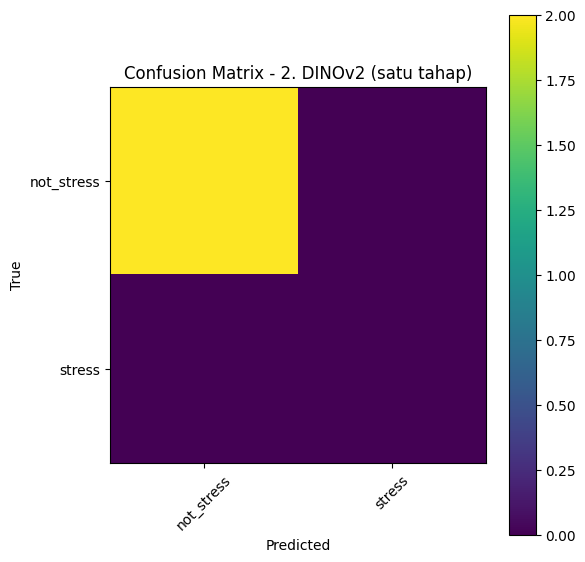

2. DINOv2 (satu tahap): acc=1.0000, f1_macro=1.0000, matched=2 -> disimpan di E:\Magang DSC\Code - Image Classification Workflow\Data_working\evaluation_results\DINOv2_satu_tahap


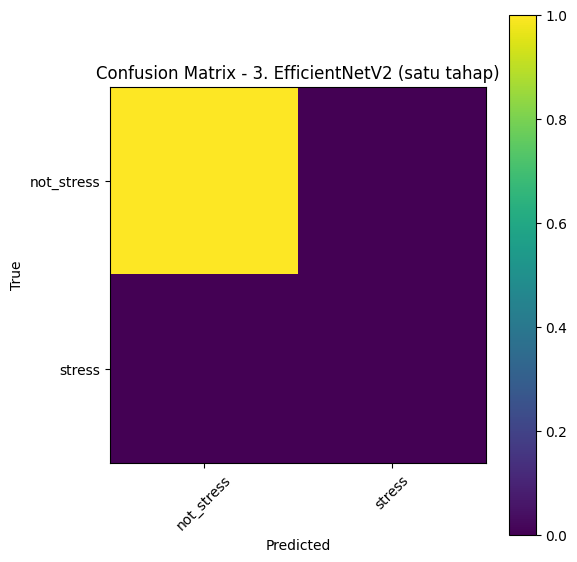

3. EfficientNetV2 (satu tahap): acc=1.0000, f1_macro=1.0000, matched=1 -> disimpan di E:\Magang DSC\Code - Image Classification Workflow\Data_working\evaluation_results\EfficientNetV2_satu_tahap
4. YOLOv11 + DINOv2: tidak ada sampel matched, evaluasi dilewati (lihat E:\Magang DSC\Code - Image Classification Workflow\Data_working\evaluation_results\YOLOv11_+_DINOv2\classification_report.txt)
5. YOLOv11 + EfficientNetV2: tidak ada sampel matched, evaluasi dilewati (lihat E:\Magang DSC\Code - Image Classification Workflow\Data_working\evaluation_results\YOLOv11_+_EfficientNetV2\classification_report.txt)
6. YOLOv11 + Ensemble(DINOv2, EfficientNetV2): tidak ada sampel matched, evaluasi dilewati (lihat E:\Magang DSC\Code - Image Classification Workflow\Data_working\evaluation_results\YOLOv11_+_EnsembleDINOv2_EfficientNetV2\classification_report.txt)


In [10]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

pipelines = {
    "1. YOLOv11 (satu tahap)": lambda p: predict_yolo_single_stage(yolo_config1, p),
    "2. DINOv2 (satu tahap)": lambda p: predict_torchvision_detector(config2_model, p),
    "3. EfficientNetV2 (satu tahap)": lambda p: predict_torchvision_detector(config3_model, p),
    "4. YOLOv11 + DINOv2": lambda p: predict_two_stage(
        lambda pp: predict_yolo_single_stage(yolo_config1, pp), config4_classifier, p
    ),
    "5. YOLOv11 + EfficientNetV2": lambda p: predict_two_stage(
        lambda pp: predict_yolo_single_stage(yolo_config1, pp), config5_classifier, p
    ),
    "6. YOLOv11 + Ensemble(DINOv2, EfficientNetV2)": lambda p: predict_two_stage_ensemble(
        lambda pp: predict_yolo_single_stage(yolo_config1, pp), [config4_classifier, config5_classifier], p
    ),
}

label_ids = sorted(id_to_class.keys())
target_names = [id_to_class[i] for i in label_ids]

EVAL_DIR = os.path.join(WORK_DIR, "evaluation_results")  # PATCH: folder baru untuk hasil evaluasi tiap eksperimen
os.makedirs(EVAL_DIR, exist_ok=True)

def safe_folder_name(name):
    keep = name.split(". ", 1)[-1]
    for ch in "()/,":
        keep = keep.replace(ch, "")
    return keep.strip().replace(" ", "_")

def evaluate_and_save(name, predict_fn, save_dir):
    y_true, y_pred = evaluate_pipeline(predict_fn)
    acc = accuracy_score(y_true, y_pred) if y_true else float("nan")
    f1 = f1_score(y_true, y_pred, average="macro") if y_true else float("nan")

    os.makedirs(save_dir, exist_ok=True)
    report_path = os.path.join(save_dir, "classification_report.txt")
    cm_path = os.path.join(save_dir, "confusion_matrix.png")

    if not y_true:
        with open(report_path, "w") as f:
            f.write(f"Eksperimen: {name}\nTidak ada sampel yang cocok untuk dievaluasi.\n")
        print(f"{name}: tidak ada sampel matched, evaluasi dilewati (lihat {report_path})")
        return {"accuracy": acc, "f1_macro": f1, "n_matched": 0}

    report_text = classification_report(y_true, y_pred, labels=label_ids, target_names=target_names, zero_division=0)
    with open(report_path, "w") as f:
        f.write(f"Eksperimen: {name}\n")
        f.write(f"accuracy={acc:.4f}, f1_macro={f1:.4f}, n_matched={len(y_true)}\n\n")
        f.write(report_text)

    cm = confusion_matrix(y_true, y_pred, labels=label_ids)
    plt.figure(figsize=(6, 6))
    plt.imshow(cm)
    plt.xticks(range(len(target_names)), target_names, rotation=45)
    plt.yticks(range(len(target_names)), target_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.colorbar()
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.savefig(cm_path, dpi=200, bbox_inches="tight")
    plt.show()

    print(f"{name}: acc={acc:.4f}, f1_macro={f1:.4f}, matched={len(y_true)} -> disimpan di {save_dir}")
    return {"accuracy": acc, "f1_macro": f1, "n_matched": len(y_true)}

results_summary = {}
for name, fn in pipelines.items():
    save_dir = os.path.join(EVAL_DIR, safe_folder_name(name))
    results_summary[name] = evaluate_and_save(name, fn, save_dir)

In [11]:
results_df = pd.DataFrame(results_summary).T.sort_values("f1_macro", ascending=False)
results_df


,accuracy,f1_macro,n_matched
2. DINOv2 (satu tahap),1.0,1.0,2.0
3. EfficientNetV2 (satu tahap),1.0,1.0,1.0
1. YOLOv11 (satu tahap),NaN,NaN,0.0
4. YOLOv11 + DINOv2,NaN,NaN,0.0
5. YOLOv11 + EfficientNetV2,NaN,NaN,0.0
"6. YOLOv11 + Ensemble(DINOv2, EfficientNetV2)",NaN,NaN,0.0


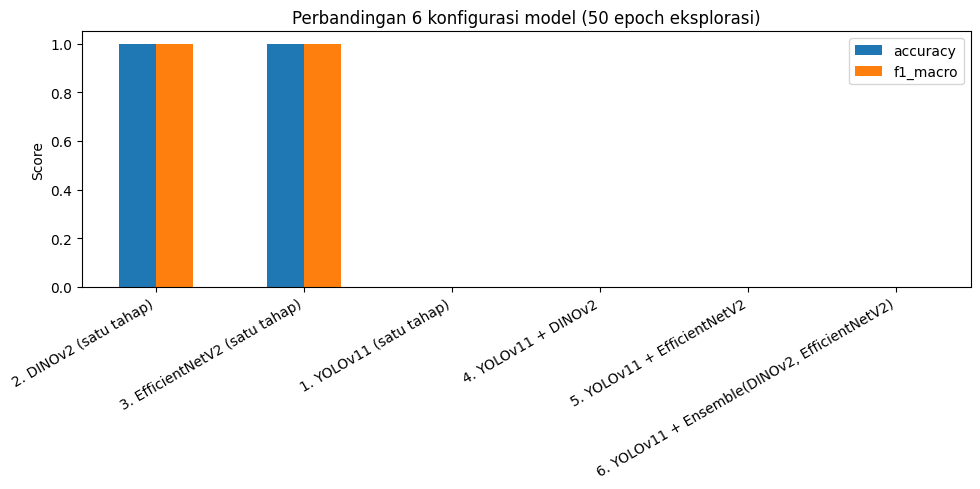

In [12]:
results_df[["accuracy", "f1_macro"]].plot(kind="bar", figsize=(10, 5))
plt.title(f"Perbandingan 6 konfigurasi model ({EXPLORE_EPOCHS} epoch eksplorasi)")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 9. Ringkasan Konfigurasi Terbaik

Confusion matrix & classification report untuk **semua 6 konfigurasi** sudah tersimpan di langkah 8.1 di atas (`WORK_DIR/evaluation_results/<nama_eksperimen>/`). Cell di bawah cuma menunjukkan mana yang terbaik (F1 macro tertinggi) dan lokasi file hasilnya.

Konfigurasi terbaik: 2. DINOv2 (satu tahap)
Classification report: E:\Magang DSC\Code - Image Classification Workflow\Data_working\evaluation_results\DINOv2_satu_tahap\classification_report.txt
Confusion matrix: E:\Magang DSC\Code - Image Classification Workflow\Data_working\evaluation_results\DINOv2_satu_tahap\confusion_matrix.png


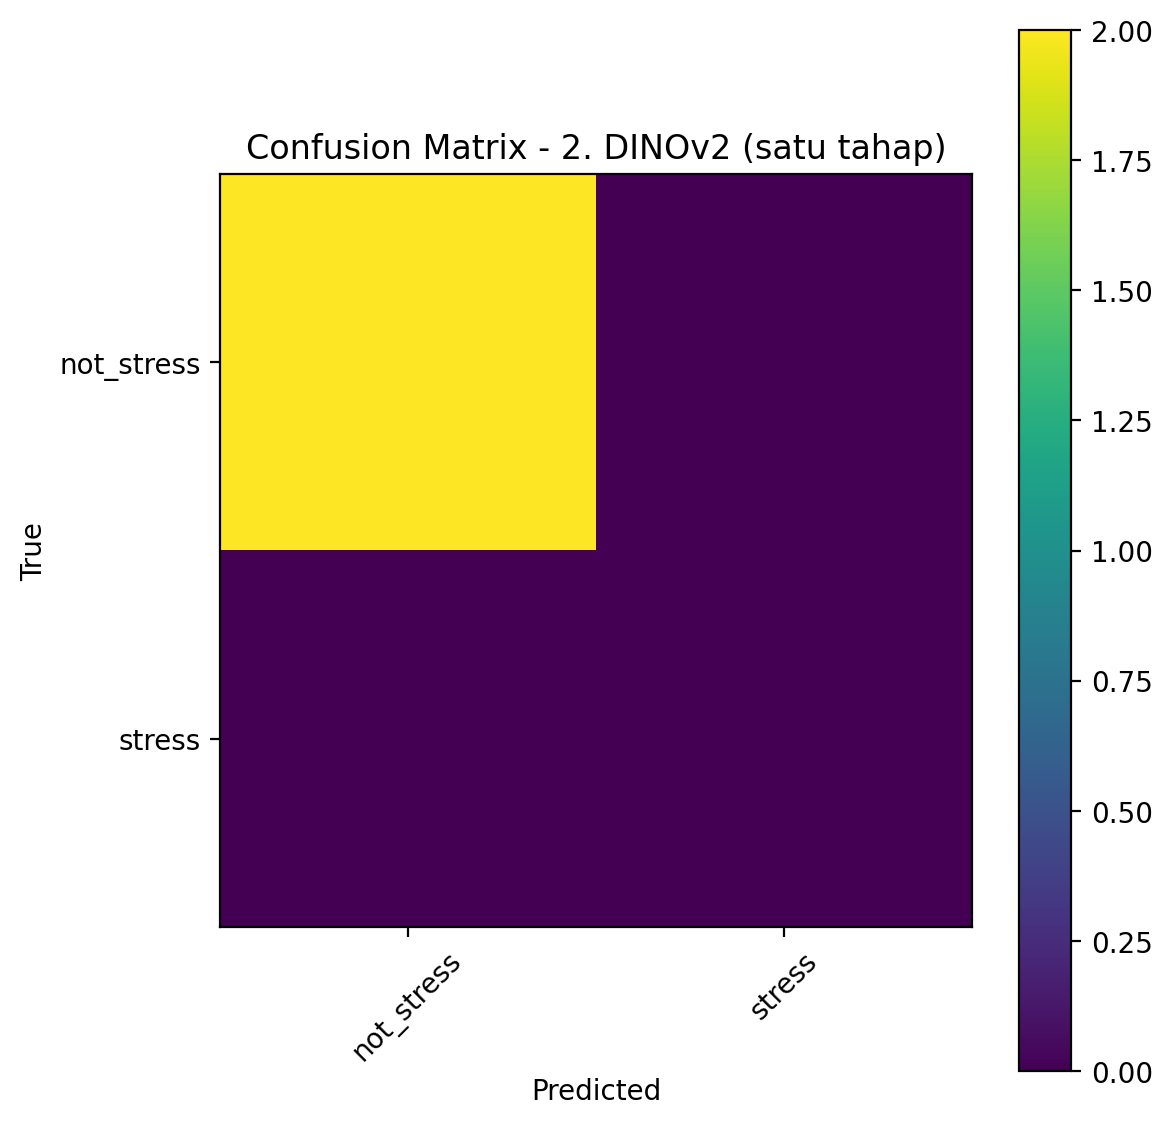

In [13]:
best_config = results_df.index[0]
best_dir = os.path.join(EVAL_DIR, safe_folder_name(best_config))

print("Konfigurasi terbaik:", best_config)
print("Classification report:", os.path.join(best_dir, "classification_report.txt"))
print("Confusion matrix:", os.path.join(best_dir, "confusion_matrix.png"))

from IPython.display import Image as IPyImage, display
display(IPyImage(filename=os.path.join(best_dir, "confusion_matrix.png")))

---

## 10. Evaluasi Lanjutan (STEP 8 — `alur_deteksi_stres_ayam.md`)

Evaluasi di atas (bagian 8/8.1/9) baru mencakup accuracy, f1-macro, classification report, dan confusion matrix. Bagian ini melengkapi sesuai dokumen alur:
- **Classifier**: accuracy, **balanced accuracy**, precision/recall(sensitivity)/**specificity**/F1 per kelas, **Cohen's kappa**, **ROC-AUC**, **PR-AUC**, kalibrasi probabilitas (**calibration curve, Brier score, Expected Calibration Error**).
- **Operasional**: waktu inferensi (ms), FPS, jumlah parameter, kebutuhan memori.
- **Detektor (YOLOv11)**: precision, recall, AP50, AP75, mAP50-95, **missed detection rate**.
- **Validasi eksternal**: kerangka fungsi untuk data dari kandang mitra (belum ada datanya di notebook ini).

In [14]:
# === Versi "scored" dari fungsi prediksi -- mengembalikan juga skor probabilitas
# kelas 'stress' per objek, dibutuhkan untuk ROC-AUC / PR-AUC / kalibrasi ===

stress_id = class_to_id["stress"]

def predict_yolo_single_stage_scored(model, image_path):
    result = model(image_path, verbose=False)[0]
    boxes = result.boxes.xyxy.cpu().numpy().tolist()
    labels = result.boxes.cls.cpu().numpy().astype(int).tolist()
    confs = result.boxes.conf.cpu().numpy().tolist()
    # Confidence Ultralytics ~ skor kelas yang diprediksi (bukan softmax 2 kelas penuh);
    # dipakai sebagai proxy skor probabilitas kelas 'stress'.
    scores_stress = [c if lbl == stress_id else 1 - c for lbl, c in zip(labels, confs)]
    return boxes, labels, scores_stress

def predict_torchvision_detector_scored(model, image_path, device="cpu", score_thresh=0.5):
    model.eval()
    img = Image.open(image_path).convert("RGB")
    tensor = TF.to_tensor(img).unsqueeze(0).to(device)
    with torch.no_grad():
        out = model(tensor)[0]
    keep = out["scores"] >= score_thresh
    boxes = out["boxes"][keep].cpu().numpy().tolist()
    labels = (out["labels"][keep] - 1).cpu().numpy().tolist()
    confs = out["scores"][keep].cpu().numpy().tolist()
    scores_stress = [c if lbl == stress_id else 1 - c for lbl, c in zip(labels, confs)]
    return boxes, labels, scores_stress

def predict_two_stage_scored(detector_predict_fn, classifier, image_path, device="cpu"):
    boxes, _ = detector_predict_fn(image_path)
    img = Image.open(image_path).convert("RGB")
    labels, scores_stress = [], []
    classifier.eval()
    for b in boxes:
        crop = img.crop(tuple(b)).resize((224, 224))
        tensor = TF.to_tensor(crop).unsqueeze(0).to(device)
        with torch.no_grad():
            probs = torch.softmax(classifier(tensor), dim=1)[0]
        labels.append(int(probs.argmax().item()))
        scores_stress.append(float(probs[stress_id].item()))
    return boxes, labels, scores_stress

def predict_two_stage_ensemble_scored(detector_predict_fn, classifiers, image_path, device="cpu"):
    boxes, _ = detector_predict_fn(image_path)
    img = Image.open(image_path).convert("RGB")
    labels, scores_stress = [], []
    for c in classifiers:
        c.eval()
    for b in boxes:
        crop = img.crop(tuple(b)).resize((224, 224))
        tensor = TF.to_tensor(crop).unsqueeze(0).to(device)
        probs_list = []
        with torch.no_grad():
            for c in classifiers:
                probs_list.append(torch.softmax(c(tensor), dim=1))
        avg_prob = torch.stack(probs_list).mean(0)[0]
        labels.append(int(avg_prob.argmax().item()))
        scores_stress.append(float(avg_prob[stress_id].item()))
    return boxes, labels, scores_stress

pipelines_scored = {
    "1. YOLOv11 (satu tahap)": lambda p: predict_yolo_single_stage_scored(yolo_config1, p),
    "2. DINOv2 (satu tahap)": lambda p: predict_torchvision_detector_scored(config2_model, p),
    "3. EfficientNetV2 (satu tahap)": lambda p: predict_torchvision_detector_scored(config3_model, p),
    "4. YOLOv11 + DINOv2": lambda p: predict_two_stage_scored(
        lambda pp: predict_yolo_single_stage(yolo_config1, pp), config4_classifier, p
    ),
    "5. YOLOv11 + EfficientNetV2": lambda p: predict_two_stage_scored(
        lambda pp: predict_yolo_single_stage(yolo_config1, pp), config5_classifier, p
    ),
    "6. YOLOv11 + Ensemble(DINOv2, EfficientNetV2)": lambda p: predict_two_stage_ensemble_scored(
        lambda pp: predict_yolo_single_stage(yolo_config1, pp), [config4_classifier, config5_classifier], p
    ),
}

In [15]:
def evaluate_pipeline_full(predict_fn_scored, iou_thresh=0.5):
    """Sama seperti evaluate_pipeline, tapi juga mengumpulkan skor probabilitas
    (untuk ROC-AUC/PR-AUC/kalibrasi) dan menghitung missed detection rate."""
    test_img_dir = os.path.join(YOLO_DIR, "images", "test")
    y_true, y_pred, y_score = [], [], []
    n_gt_total, n_matched_total = 0, 0

    for file_name in os.listdir(test_img_dir):
        image_path = os.path.join(test_img_dir, file_name)
        gt_boxes, gt_labels = get_ground_truth(file_name)
        n_gt_total += len(gt_boxes)
        pred_boxes, pred_labels, pred_scores = predict_fn_scored(image_path)

        matched = set()
        for gb, gl in zip(gt_boxes, gt_labels):
            best_iou, best_j = 0, -1
            for j, pb in enumerate(pred_boxes):
                if j in matched:
                    continue
                cur_iou = iou(gb, pb)
                if cur_iou > best_iou:
                    best_iou, best_j = cur_iou, j
            if best_iou >= iou_thresh:
                matched.add(best_j)
                y_true.append(gl)
                y_pred.append(pred_labels[best_j])
                y_score.append(pred_scores[best_j])
                n_matched_total += 1

    missed_detection_rate = 1 - (n_matched_total / n_gt_total) if n_gt_total > 0 else float("nan")
    return y_true, y_pred, y_score, missed_detection_rate

In [16]:
from sklearn.metrics import (
    balanced_accuracy_score, precision_recall_fscore_support, cohen_kappa_score,
    roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
)

def specificity_per_class(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    specs = []
    for i in range(len(labels)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        specs.append(tn / (tn + fp) if (tn + fp) > 0 else float("nan"))
    return dict(zip([id_to_class[l] for l in labels], specs))

def expected_calibration_error(y_true_bin, y_score, n_bins=10):
    y_true_bin = np.asarray(y_true_bin)
    y_score = np.asarray(y_score)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (y_score > lo) & (y_score <= hi) if i > 0 else (y_score >= lo) & (y_score <= hi)
        if mask.sum() == 0:
            continue
        acc_bin = y_true_bin[mask].mean()
        conf_bin = y_score[mask].mean()
        ece += (mask.sum() / len(y_score)) * abs(acc_bin - conf_bin)
    return ece

def compute_full_classification_metrics(y_true, y_pred, y_score):
    y_true_bin = [1 if yt == stress_id else 0 for yt in y_true]  # 1 = stress

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
    }

    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=label_ids, zero_division=0)
    for i, cls in enumerate(target_names):
        metrics[f"precision_{cls}"] = prec[i]
        metrics[f"recall_sensitivity_{cls}"] = rec[i]
        metrics[f"f1_{cls}"] = f1[i]
    for cls, s in specificity_per_class(y_true, y_pred, label_ids).items():
        metrics[f"specificity_{cls}"] = s

    if len(set(y_true_bin)) > 1:
        metrics["roc_auc"] = roc_auc_score(y_true_bin, y_score)
        metrics["pr_auc"] = average_precision_score(y_true_bin, y_score)
        metrics["brier_score"] = brier_score_loss(y_true_bin, y_score)
        metrics["ece"] = expected_calibration_error(y_true_bin, y_score)
    else:
        metrics["roc_auc"] = metrics["pr_auc"] = metrics["brier_score"] = metrics["ece"] = float("nan")

    return metrics, y_true_bin

def measure_operational_metrics(predict_fn_scored, sample_paths, model_for_params=None):
    times = []
    for p in sample_paths:
        t0 = time.time()
        predict_fn_scored(p)
        times.append(time.time() - t0)
    mean_time = float(np.mean(times)) if times else float("nan")

    n_params, mem_mb = None, None
    if model_for_params is not None:
        try:
            n_params = sum(p.numel() for p in model_for_params.parameters())
            mem_mb = sum(p.numel() * p.element_size() for p in model_for_params.parameters()) / (1024 ** 2)
        except Exception:
            pass

    return {
        "avg_latency_ms": mean_time * 1000,
        "fps": (1.0 / mean_time) if mean_time > 0 else float("nan"),
        "n_params": n_params,
        "memory_mb": mem_mb,
    }

In [17]:
import time

# Model dipakai untuk hitung parameter/memori tiap pipeline (None utk YOLO -- dihitung terpisah lewat .val())
params_model_map = {
    "1. YOLOv11 (satu tahap)": None,
    "2. DINOv2 (satu tahap)": config2_model,
    "3. EfficientNetV2 (satu tahap)": config3_model,
    "4. YOLOv11 + DINOv2": config4_classifier,
    "5. YOLOv11 + EfficientNetV2": config5_classifier,
    "6. YOLOv11 + Ensemble(DINOv2, EfficientNetV2)": config4_classifier,  # ensemble: dominan biaya di 2 classifier
}

test_img_dir = os.path.join(YOLO_DIR, "images", "test")
sample_paths_for_timing = [os.path.join(test_img_dir, f) for f in os.listdir(test_img_dir)[:10]]

full_metrics_summary = {}
calibration_data = {}

for name, predict_fn_scored in pipelines_scored.items():
    y_true, y_pred, y_score, missed_rate = evaluate_pipeline_full(predict_fn_scored)
    if not y_true:
        print(f"{name}: tidak ada sampel matched, dilewati.")
        continue

    metrics, y_true_bin = compute_full_classification_metrics(y_true, y_pred, y_score)
    metrics["missed_detection_rate"] = missed_rate

    op_metrics = measure_operational_metrics(predict_fn_scored, sample_paths_for_timing, params_model_map[name])
    metrics.update(op_metrics)

    full_metrics_summary[name] = metrics
    calibration_data[name] = (y_true_bin, y_score)

    save_dir = os.path.join(EVAL_DIR, safe_folder_name(name))
    os.makedirs(save_dir, exist_ok=True)
    with open(os.path.join(save_dir, "full_metrics.json"), "w") as f:
        json.dump(metrics, f, indent=2, default=str)

full_metrics_df = pd.DataFrame(full_metrics_summary).T
display(full_metrics_df)
full_metrics_df.to_csv(os.path.join(EVAL_DIR, "full_metrics_summary.csv"))
print("Metrik lengkap tiap eksperimen disimpan ke", os.path.join(EVAL_DIR, "full_metrics_summary.csv"))

1. YOLOv11 (satu tahap): tidak ada sampel matched, dilewati.


c:\Users\Lenovo ThinkPad T480\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Lenovo ThinkPad T480\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\Users\Lenovo ThinkPad T480\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:897: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)
c:\Users\Lenovo ThinkPad T480\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:534

4. YOLOv11 + DINOv2: tidak ada sampel matched, dilewati.
5. YOLOv11 + EfficientNetV2: tidak ada sampel matched, dilewati.
6. YOLOv11 + Ensemble(DINOv2, EfficientNetV2): tidak ada sampel matched, dilewati.


,accuracy,balanced_accuracy,f1_macro,cohen_kappa,precision_not_stress,recall_sensitivity_not_stress,f1_not_stress,precision_stress,recall_sensitivity_stress,f1_stress,specificity_not_stress,specificity_stress,roc_auc,pr_auc,brier_score,ece,missed_detection_rate,avg_latency_ms,fps,n_params,memory_mb
2. DINOv2 (satu tahap),1.0,1.0,1.0,NaN,1.0,1.0,1.0,0.0,0.0,0.0,NaN,1.0,NaN,NaN,NaN,NaN,0.6,2563.423395,0.390103,43746522.0,166.879738
3. EfficientNetV2 (satu tahap),1.0,1.0,1.0,NaN,1.0,1.0,1.0,0.0,0.0,0.0,NaN,1.0,NaN,NaN,NaN,NaN,0.8,2019.844532,0.495088,100311722.0,382.658852


Metrik lengkap tiap eksperimen disimpan ke E:\Magang DSC\Code - Image Classification Workflow\Data_working\evaluation_results\full_metrics_summary.csv


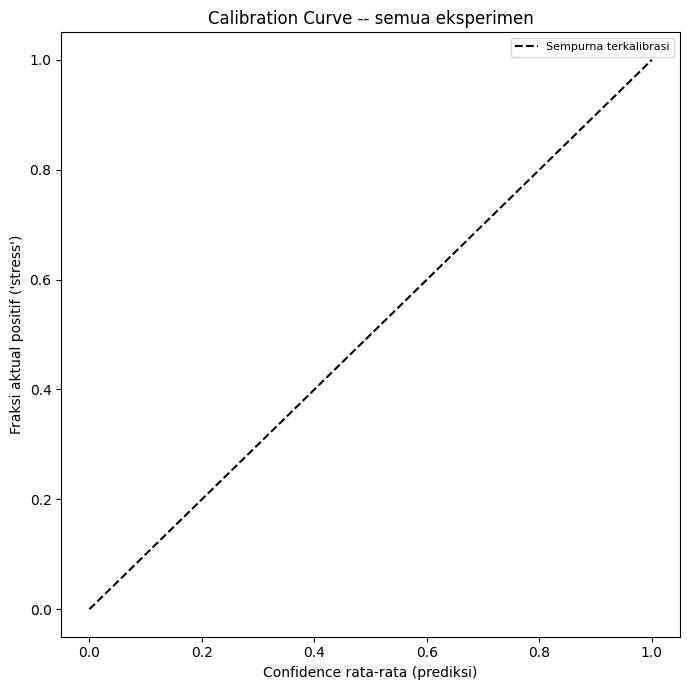

In [18]:
# Calibration curve per eksperimen (kelas 'stress')
from sklearn.calibration import calibration_curve

plt.figure(figsize=(7, 7))
plt.plot([0, 1], [0, 1], "k--", label="Sempurna terkalibrasi")
for name, (y_true_bin, y_score) in calibration_data.items():
    if len(set(y_true_bin)) < 2:
        continue
    frac_pos, mean_pred = calibration_curve(y_true_bin, y_score, n_bins=5)
    plt.plot(mean_pred, frac_pos, marker="o", label=name)
plt.xlabel("Confidence rata-rata (prediksi)")
plt.ylabel("Fraksi aktual positif ('stress')")
plt.title("Calibration Curve -- semua eksperimen")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "calibration_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

### Evaluasi Detektor (YOLOv11) — precision, recall, AP50, AP75, mAP50-95

Metrik detektor murni (sebelum digabung dengan klasifikasi), memakai validasi bawaan Ultralytics pada split `test`.

In [19]:
yolo_val_metrics = yolo_config1.val(
    data=os.path.join(YOLO_DIR, "data.yaml"), split="test", verbose=False
)

yolo_detector_metrics = {
    "precision": float(yolo_val_metrics.box.mp),
    "recall": float(yolo_val_metrics.box.mr),
    "AP50": float(yolo_val_metrics.box.map50),
    "AP75": float(yolo_val_metrics.box.map75),
    "mAP50-95": float(yolo_val_metrics.box.map),
}
# missed detection rate detektor murni (independen dari klasifikasi) diambil dari evaluate_pipeline_full
# konfigurasi 1 (YOLOv11 satu tahap) di atas, kolom 'missed_detection_rate'.
yolo_detector_metrics["missed_detection_rate_from_pipeline1"] = full_metrics_summary.get(
    "1. YOLOv11 (satu tahap)", {}
).get("missed_detection_rate", float("nan"))

print("Evaluasi Detektor YOLOv11:")
for k, v in yolo_detector_metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

with open(os.path.join(EVAL_DIR, "yolo_detector_metrics.json"), "w") as f:
    json.dump(yolo_detector_metrics, f, indent=2, default=str)

Ultralytics 8.4.103  Python-3.11.9 torch-2.14.0+cpu CPU (Intel Core i7-8550U 1.80GHz)
val: Fast image access  (ping: 0.10.1 ms, read: 543.4182.3 MB/s, size: 82.9 KB)
val: Scanning E:\Magang DSC\Code - Image Classification Workflow\Data_working\yolo_detect_dataset\labels\test... 2 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2/2 154.3it/s 0.0s
val: New cache created: E:\Magang DSC\Code - Image Classification Workflow\Data_working\yolo_detect_dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.4it/s 0.4s
                   all          2          5    0.00637        0.6       0.28      0.203
Speed: 0.7ms preprocess, 181.4ms inference, 0.0ms loss, 4.7ms postprocess per image
Results saved to E:\Magang DSC\Code - Image Classification Workflow\runs\detect\val
Evaluasi Detektor YOLOv11:
  precision: 0.0064
  recall: 0.6000
  AP50: 0.2795
  AP75: 0.2794
  mAP50-95: 0.2034
  missed_detection_rate_fro

### Validasi Eksternal (kandang mitra)

Sesuai dokumen alur, validasi bertahap = (1) internal [sudah di atas] → (2) cross-validation per individu/video/sesi → (3) **validasi eksternal** memakai citra dari kandang mitra yang berbeda dari data pelatihan (pencahayaan, sudut kamera, jenis ayam, kepadatan kandang, latar berbeda).

Notebook ini **belum memiliki dataset eksternal**, jadi hanya disediakan kerangka fungsinya — cukup arahkan `external_test_img_dir` dan `external_test_df` (format sama seperti `test_df`) ke data kandang mitra saat tersedia.

In [20]:
def run_external_validation(external_test_img_dir, external_test_df, predict_fn_scored, iou_thresh=0.5):
    """Kerangka validasi eksternal (Step 8, poin 3). Menerima folder citra + dataframe
    ground truth (schema sama seperti test_df/YOLO_DIR) dari kandang mitra yang berbeda
    dari data pelatihan, lalu menjalankan evaluasi yang sama seperti evaluate_pipeline_full."""
    def _get_gt(file_name):
        rows = external_test_df[external_test_df["file_name"] == file_name]
        boxes = [[r.x, r.y, r.x + r.w, r.y + r.h] for r in rows.itertuples()]
        labels = [class_to_id[r.label] for r in rows.itertuples()]
        return boxes, labels

    y_true, y_pred, y_score = [], [], []
    n_gt_total, n_matched_total = 0, 0
    for file_name in os.listdir(external_test_img_dir):
        image_path = os.path.join(external_test_img_dir, file_name)
        gt_boxes, gt_labels = _get_gt(file_name)
        n_gt_total += len(gt_boxes)
        pred_boxes, pred_labels, pred_scores = predict_fn_scored(image_path)
        matched = set()
        for gb, gl in zip(gt_boxes, gt_labels):
            best_iou, best_j = 0, -1
            for j, pb in enumerate(pred_boxes):
                if j in matched:
                    continue
                cur_iou = iou(gb, pb)
                if cur_iou > best_iou:
                    best_iou, best_j = cur_iou, j
            if best_iou >= iou_thresh:
                matched.add(best_j)
                y_true.append(gl); y_pred.append(pred_labels[best_j]); y_score.append(pred_scores[best_j])
                n_matched_total += 1
    missed_rate = 1 - (n_matched_total / n_gt_total) if n_gt_total > 0 else float("nan")
    if not y_true:
        print("Validasi eksternal: tidak ada sampel matched.")
        return None
    metrics, _ = compute_full_classification_metrics(y_true, y_pred, y_score)
    metrics["missed_detection_rate"] = missed_rate
    return metrics

# Contoh pemanggilan setelah data kandang mitra tersedia:
# external_metrics = run_external_validation(
#     "/path/ke/kandang_mitra/images", external_test_df, pipelines_scored["6. YOLOv11 + Ensemble(DINOv2, EfficientNetV2)"]
# )
print("Kerangka run_external_validation() siap dipakai begitu data kandang mitra tersedia.")

Kerangka run_external_validation() siap dipakai begitu data kandang mitra tersedia.


---

## 11. Interpretabilitas Visual (STEP 9 — `alur_deteksi_stres_ayam.md`)

- **Grad-CAM** untuk model berbasis CNN (EfficientNetV2, `config5_classifier`).
- **Attention map** untuk model berbasis transformer (DINOv2, `config4_classifier`).

Tujuan: memastikan keputusan model berasal dari bagian tubuh ayam yang relevan (kepala, mata, paruh, sayap, kaki, ekor, bulu) — bukan dari latar belakang kandang atau artefak lain.

In [23]:
def grad_cam_effnetv2(model, image_path, target_class=None, device="cpu"):
    """Grad-CAM pada blok konvolusi terakhir EfficientNetV2Classifier.model.features."""
    model.eval()
    img = Image.open(image_path).convert("RGB").resize((224, 224))
    tensor = TF.to_tensor(img).unsqueeze(0).to(device)
    tensor.requires_grad_(True)

    activations, gradients = {}, {}
    target_layer = model.model.features[-1]

    def fwd_hook(module, inp, out):
        activations["value"] = out

    def bwd_hook(module, grad_in, grad_out):
        gradients["value"] = grad_out[0]

    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_full_backward_hook(bwd_hook)

    out = model(tensor)
    if target_class is None:
        target_class = int(out.argmax(1).item())
    model.zero_grad()
    out[0, target_class].backward()
    h1.remove(); h2.remove()

    acts = activations["value"][0]
    grads = gradients["value"][0]
    weights = grads.mean(dim=(1, 2))
    cam = torch.relu((weights[:, None, None] * acts).sum(0))
    cam = cam / (cam.max() + 1e-8)
    cam_np = cam.detach().cpu().numpy()
    cam_resized = np.array(Image.fromarray((cam_np * 255).astype(np.uint8)).resize((224, 224)))

    return np.array(img), cam_resized, target_class


def attention_map_dinov2(model, image_path, device="cpu"):
    """Attention map dari token CLS ke seluruh patch token pada layer terakhir DINOv2."""
    model.eval()
    img = Image.open(image_path).convert("RGB").resize((224, 224))
    tensor = TF.to_tensor(img).unsqueeze(0).to(device)

    with torch.no_grad():
        backbone_out = model.backbone(tensor, output_attentions=True, output_hidden_states=True)
        pred_class = int(model(tensor).argmax(1).item())

    # Coba gunakan attention weights; jika kosong, fallback ke hidden states
    if backbone_out.attentions and len(backbone_out.attentions) > 0:
        last_attn = backbone_out.attentions[-1][0]   # (num_heads, tokens, tokens)
        cls_attn = last_attn.mean(0)[0, 1:]           # rata-rata head, CLS -> semua patch token
    else:
        # Fallback: gunakan norma L2 dari hidden state layer terakhir sebagai saliency
        last_hidden = backbone_out.hidden_states[-1][0]  # (tokens, hidden_dim)
        cls_attn = last_hidden[1:].norm(dim=-1)           # (num_patches,)

    grid = int(cls_attn.shape[0] ** 0.5)
    attn_map = cls_attn.reshape(grid, grid).cpu().numpy()
    attn_map = attn_map / (attn_map.max() + 1e-8)
    attn_resized = np.array(Image.fromarray((attn_map * 255).astype(np.uint8)).resize((224, 224)))

    return np.array(img), attn_resized, pred_class


def show_interpretability(orig, heatmap, title):
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1); plt.imshow(orig); plt.title("Citra asli"); plt.axis("off")
    plt.subplot(1, 2, 2); plt.imshow(orig); plt.imshow(heatmap, cmap="jet", alpha=0.45)
    plt.title(title); plt.axis("off")
    plt.tight_layout(); plt.show()


=== Grad-CAM (EfficientNetV2) ===


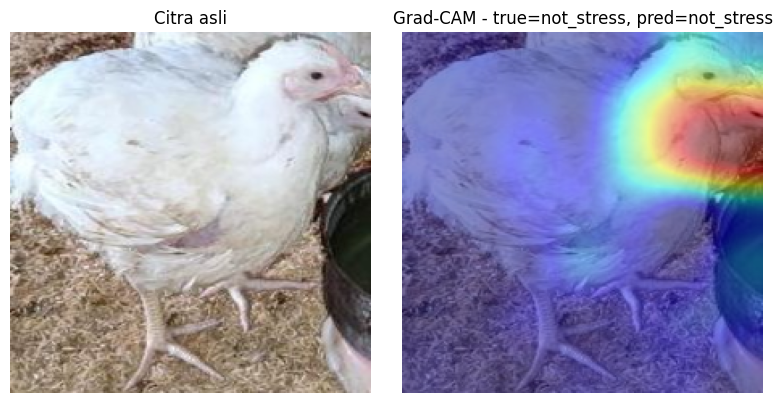

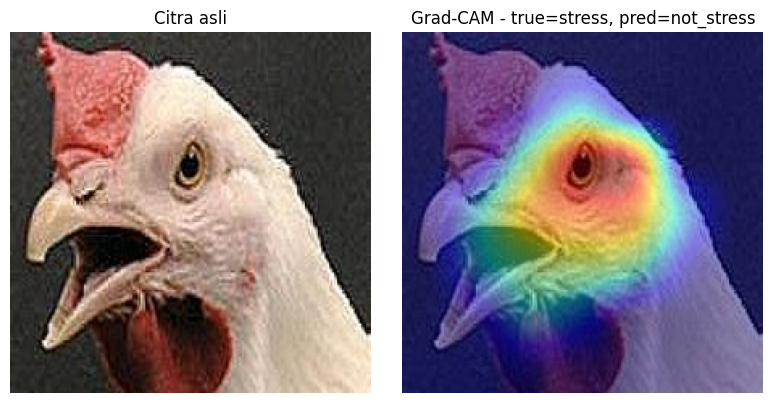

=== Attention Map (DINOv2) ===


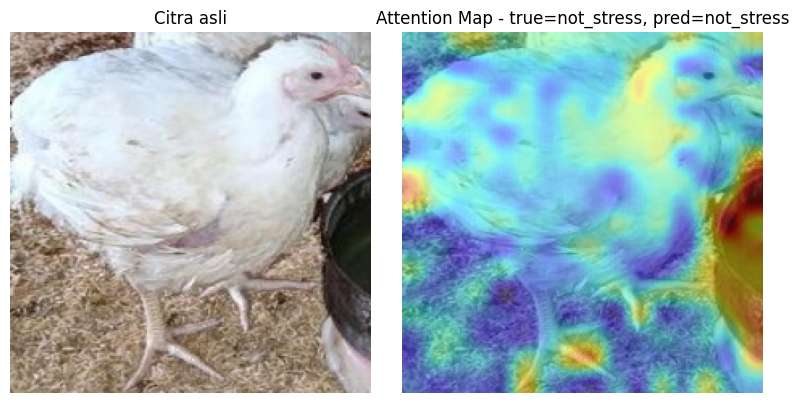

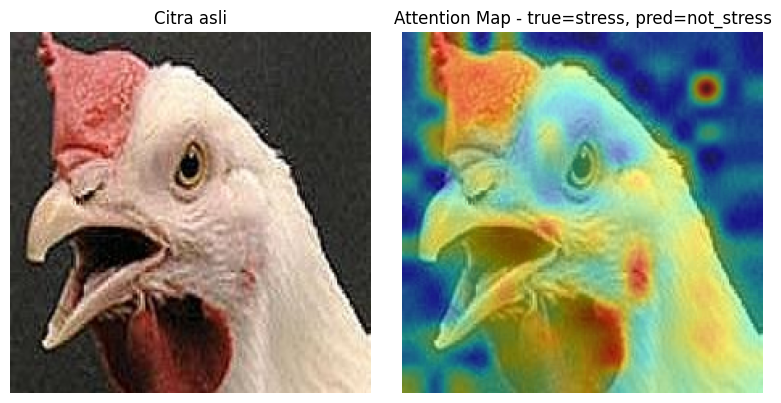


>> Periksa visual: heatmap seharusnya menyorot bagian tubuh ayam (kepala, mata, paruh,
   sayap, kaki, ekor, bulu) -- bukan latar belakang kandang atau artefak lain.


In [24]:
# Ambil satu contoh citra per kelas biner dari test set untuk divisualisasikan
sample_paths_by_class = {}
for cls in class_to_id:
    folder = os.path.join(DEST, "test", cls)
    if os.path.isdir(folder):
        files = os.listdir(folder)
        if files:
            sample_paths_by_class[cls] = os.path.join(folder, files[0])

print("=== Grad-CAM (EfficientNetV2) ===")
for cls, path in sample_paths_by_class.items():
    orig, cam, pred = grad_cam_effnetv2(config5_classifier, path)
    show_interpretability(orig, cam, f"Grad-CAM - true={cls}, pred={id_to_class[pred]}")

print("=== Attention Map (DINOv2) ===")
for cls, path in sample_paths_by_class.items():
    orig, attn, pred = attention_map_dinov2(config4_classifier, path)
    show_interpretability(orig, attn, f"Attention Map - true={cls}, pred={id_to_class[pred]}")

print("\n>> Periksa visual: heatmap seharusnya menyorot bagian tubuh ayam (kepala, mata, paruh,")
print("   sayap, kaki, ekor, bulu) -- bukan latar belakang kandang atau artefak lain.")

## Catatan lanjutan

- Hasil eksplorasi ini dipakai untuk **memilih** konfigurasi paling menjanjikan, bukan hasil final.
- Konfigurasi terbaik bisa dilanjutkan dengan epoch lebih banyak, tuning learning rate/anchor, dan (kalau tersedia) GPU untuk mempercepat training detektor DINOv2/EfficientNetV2 yang dibangun dari nol lewat torchvision `FasterRCNN`.
- Karena DINOv2 & EfficientNetV2 di sini dipasang sebagai backbone `FasterRCNN` custom (bukan detektor bawaan seperti YOLO), performanya sangat bergantung pada ukuran/rasio anchor — sesuaikan dengan ukuran objek ayam di dataset kalau hasil deteksi kurang bagus.
- Semua path kerja ada di bawah `WORK_DIR` (`Data_working`); folder dataset asli (`RAW_DIR`) tidak pernah ditulisi di ketiga notebook ini.
- **PATCH:** classification report + confusion matrix untuk keenam eksperimen tersimpan permanen di `WORK_DIR/evaluation_results/`, jadi tidak perlu menjalankan ulang notebook ini hanya untuk melihat hasil eksperimen selain yang terbaik.- **PATCH (Step 8 MD):** metrik lengkap (balanced accuracy, specificity, Cohen's kappa, ROC-AUC, PR-AUC, kalibrasi Brier/ECE, operasional latency/FPS/params/memori) tersimpan di `WORK_DIR/evaluation_results/full_metrics_summary.csv` dan `full_metrics.json` per eksperimen; metrik detektor YOLOv11 murni di `yolo_detector_metrics.json`. Validasi eksternal baru berupa kerangka fungsi (`run_external_validation`) karena belum ada dataset dari kandang mitra.
- **PATCH (Step 9 MD):** Grad-CAM (EfficientNetV2) dan attention map (DINOv2) sudah divisualisasikan pada bagian Interpretabilitas Visual di atas, untuk memastikan model fokus pada bagian tubuh ayam yang relevan.
